# 词向量：从中文词到向量

**学习目标：**对比 one-hot 向量与稠密向量，只用训练集评论训练 Skip-gram 向量，
并计算词与句子的相似度。

one-hot 向量只能区分词，无法表达相似度。Word2Vec 从上下文学习：CBOW 用上下文预测中心词，
Skip-gram 用中心词预测上下文。上下文相近会让反义词也靠得很近，
所以余弦相似度不是情感分类器；训练子集太小时，相近词也会很不稳定。


In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "请选择项目的 Python 3.12 内核。"
assert version('torch').split("+")[0] == '2.14.1', "请选择项目锁定的运行环境。"
print("Python：", sys.version.split()[0])
print('torch' + "：", version('torch'))
print("运行模式：", '课堂默认训练参数')

Python： 3.12.12
torch： 2.14.1
运行模式： 课堂默认训练参数


**预期输出：**

```text
Python： 3.12.12
torch： 2.14.1
运行模式： 课堂默认训练参数
```

In [2]:
from pathlib import Path
import os
import sys

# 不依赖当前工作目录，向上找到中文课程根目录。
start = Path.cwd().resolve()
COURSE = next((p for p in [start, *start.parents]
               if (p / "CHINESE_COURSE_ROOT").is_file()), None)
if COURSE is None:
    raise RuntimeError("请在项目根目录（中文课程）中启动 Jupyter。")
ENGLISH = COURSE / "english"
# 中文专用模块在仓库根 common/，与英文课程共享的数据与检测模块在 english/common。
sys.path.insert(0, str(ENGLISH / "common"))
sys.path.insert(0, str(COURSE / "common"))
# 模型权重缓存与英文课程共用一份，避免同一份权重重复下载。
os.environ.setdefault("HF_HOME", str(ENGLISH / "data" / "huggingface"))
os.environ.setdefault("TORCH_HOME", str(ENGLISH / "data" / "torch-cache"))

'/Users/will/workspace/deep-learning-lab/english/data/torch-cache'

**预期输出：**

```text
'…/deep-learning-lab/english/data/torch-cache'
```

（输出里的 `…` 代表运行本 notebook 时所在机器的仓库绝对路径前缀，你在自己机器上执行会看到自己的路径。）

In [3]:
FRAMEWORK = "pytorch"
EXPERIMENT = "word-embeddings"

import json
import random
import numpy as np
from sentiment_cn import load_reviews, tokenize, build_vocab, encode, LABELS

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
SMOKE = os.environ.get("COURSE_SMOKE", "0") == "1"
DATA = COURSE / "03-sentiment-analysis" / "data"
OUTPUT = COURSE / "03-sentiment-analysis" / "outputs" / FRAMEWORK / EXPERIMENT
OUTPUT.mkdir(parents=True, exist_ok=True)
train_rows = load_reviews(DATA, "train", 64 if SMOKE else 4000)
validation_rows = load_reviews(DATA, "validation", 32 if SMOKE else 1000)
test_rows = load_reviews(DATA, "test", 32 if SMOKE else 1000)
print("数据集划分规模：", len(train_rows), len(validation_rows), len(test_rows))
print("标签：", LABELS)

数据集划分规模： 4000 1000 856
标签： ['负面', '正面']


**预期输出：**

```text
数据集划分规模： 4000 1000 856
标签： ['负面', '正面']
```

## 1. 用训练集评论训练 Word2Vec


In [4]:
from gensim.models import Word2Vec
sentences = [tokenize(row["text"]) for row in train_rows]
word2vec = Word2Vec(sentences=sentences, vector_size=64, window=5,
                    min_count=1 if SMOKE else 2, sg=1, workers=1,
                    epochs=1 if SMOKE else 5, seed=SEED)
words = word2vec.wv.index_to_key
vectors = word2vec.wv.vectors.copy()
print("词表规模：", len(words), "向量形状：", vectors.shape)
word2vec.save(str(OUTPUT / "chinese_word2vec.model"))

/Users/will/env_dl_uv/.venv/lib/python3.12/site-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


词表规模： 10528 向量形状： (10528, 64)


**预期输出：**

```text
/Users/will/env_dl_uv/.venv/lib/python3.12/site-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
词表规模： 10528 向量形状： (10528, 64)
```

## 2. 把向量装进框架的嵌入层

矩阵的行号就是 token ID。这里复制训练好的向量并冻结它们，只做演示；
下游分类器里你可以选择继续微调这些向量。


In [5]:
import torch
embedding = torch.nn.Embedding.from_pretrained(torch.tensor(vectors), freeze=True)
word_to_id = {word: index for index, word in enumerate(words)}
example_word = "酒店" if "酒店" in word_to_id else words[0]
vector = embedding(torch.tensor([word_to_id[example_word]])).detach().numpy()[0]
print(f"词向量“{example_word}”：形状={vector.shape}")

词向量“酒店”：形状=(64,)


**预期输出：**

```text
词向量“酒店”：形状=(64,)
```

## 3. 探索词与句子的相似度


In [6]:
print("最相近的词：", word2vec.wv.most_similar(example_word, topn=min(5, len(words)-1)))

def sentence_vector(text):
    known = [word2vec.wv[word] for word in tokenize(text) if word in word2vec.wv]
    return np.mean(known, axis=0) if known else np.zeros(64, dtype=np.float32)

def cosine(a, b):
    return float(np.dot(a, b) / max(np.linalg.norm(a) * np.linalg.norm(b), 1e-8))

first = "这部电影很好看，演技也十分出色。"
second = "我喜欢这部片子，也喜欢里面的表演。"
print("句子相似度：", cosine(sentence_vector(first), sentence_vector(second)))
print("可以对比“很好”和“不太好”：取平均向量会丢掉语序信息。")

最相近的词： [('宾馆', 0.8297910094261169), ('饭店', 0.8250905871391296), ('房价', 0.8156116604804993), ('店', 0.8146984577178955), ('一家', 0.8008028864860535)]
句子相似度： 0.9159684777259827
可以对比“很好”和“不太好”：取平均向量会丢掉语序信息。


**预期输出：**

```text
最相近的词： [('宾馆', 0.8297910094261169), ('饭店', 0.8250905871391296), ('房价', 0.8156116604804993), ('店', 0.8146984577178955), ('一家', 0.8008028864860535)]
句子相似度： 0.9159684777259827
可以对比“很好”和“不太好”：取平均向量会丢掉语序信息。
```

## 4. 可视化一个投影

这是把词向量降到二维的 PCA 投影，是一种有损视图。
图上看近不代表语义等价。


图表中文字体： PingFang SC


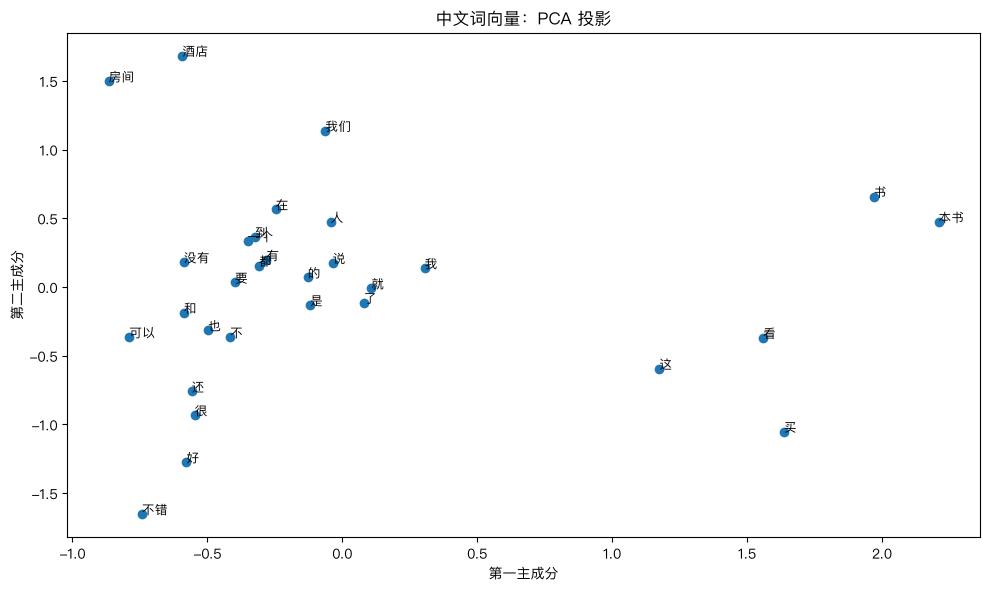

In [7]:
import matplotlib.pyplot as plt
from course_zh import setup_chinese_fonts
setup_chinese_fonts(plt)
print("图表中文字体：", setup_chinese_fonts(plt))
chosen = words[:min(30, len(words))]
matrix = np.stack([word2vec.wv[word] for word in chosen])
centered = matrix - matrix.mean(axis=0)
_, _, axes = np.linalg.svd(centered, full_matrices=False)
points = centered @ axes[:2].T
fig, axis = plt.subplots(figsize=(10, 6))
axis.scatter(points[:, 0], points[:, 1])
for word, (x, y) in zip(chosen, points):
    axis.annotate(word, (x, y), fontsize=9)
axis.set(title="中文词向量：PCA 投影", xlabel="第一主成分",
         ylabel="第二主成分")
fig.tight_layout()
fig.savefig(OUTPUT / "word_vectors.png")
plt.show()

**预期输出：**

```text
图表中文字体： PingFang SC
```

**预期输出（图片）：**

![可视化一个投影](../assets/02-word-embeddings-1.png)

*可视化一个投影*

## 练习

对比 CBOW（`sg=0`）与 Skip-gram（`sg=1`）；先增加训练数据，再解读相近词。
试一个训练集里没出现过的词，解释它为什么没有训练出来的向量。
下一节课会把“句子向量取平均”和对语序敏感的 LSTM 做对比。
